In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import dihedrals
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
from MDAnalysis.analysis.dssp import DSSP

import scipy.stats as stats


In [2]:
#                           GET RESIDUE INFORMATION FOR PYMOL INSPECTION

def residues(whichprotein, whichresidue):

    if whichprotein == "aac1":
        offset = 1
    elif whichprotein == "ucp1":
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        return 0

    toppath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/input/topol.top"
    trjpath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/traj_comp.part0001-centered.xtc"
    u = mda.Universe(toppath, trjpath, topology_format='ITP')

    n_frames = len(u.trajectory)
    n_residues = len(u.select_atoms(f"resname {whichresidue.upper()}").residues)

    #print(u.select_atoms(f"resname {whichresidue.upper()}").residues)
    resseqs = [r.resid for r in u.select_atoms(f"resname {whichresidue.upper()}").residues]

    return resseqs

In [3]:
#each element of rotamers is 0 = 180 degrees, 1 = -60 degrees, 2 = 60 degrees
#each element of hbonds is # hydrogen bonds to water
#each element of secstr is 0 if loop, 1 if helical (the protein contains no beta sheets)

def rotamer_hbond_secstr(n_residues, rotamers, hbonds, secstr, loop, resseqs):

    #thresholds to match quantitative deltadeltaG analysis
    helicity_helical_thresh = 0.75
    helicity_loop_thresh = 0.75

    hbond_dry_thresh = 0.05
    hbond_wet_thresh = 2/3

    rotamer_secstr_hbond = np.zeros((n_residues, 5)) #second index: helicity_state, hbond_state, probability of adopting each rotamer
    for nr in range(n_residues):

        #helicity state
        helical_fraction = np.sum(secstr[nr]) / len(secstr[nr])
        loop_fraction = 1 - np.sum(loop[nr]) / len(loop[nr]) #elements of the 'loop' array are 1 for helices and 0 for loops
        if helical_fraction >= helicity_helical_thresh:
            helicity_state = 2  # helical
        elif loop_fraction >= helicity_loop_thresh:
            helicity_state = 0  # loop
        else:
            helicity_state = 1  # intermediate

        #print(f"{resseqs[nr]}: {loop_fraction}")

        #hbond state
        hbond_fraction = np.sum(hbonds[nr]) / len(hbonds[nr])
        if hbond_fraction >= hbond_wet_thresh:
            hbond_state = 2  # solvated
        elif hbond_fraction <= hbond_dry_thresh:
            hbond_state = 0  # buried
        else:
            hbond_state = 1  # interfacial

        #rotamer probabilities
        rotamer_counts = np.sum(np.eye(3)[rotamers[nr]], axis=0)
        rotamer_probs = rotamer_counts/len(rotamers[nr])

        #add to array
        rotamer_secstr_hbond[nr, 0] = helicity_state
        rotamer_secstr_hbond[nr, 1] = hbond_state
        rotamer_secstr_hbond[nr,2:5] = rotamer_probs

    return rotamer_secstr_hbond


#load_process(rotamer_hbond_secstr, resn)

In [8]:
def load_process(analysis_method, resn):

    #this path actually also contains serine rotamers
    inputpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/resi_data"

    servers = ["wynton", "degrabo"]
    proteins = ["ucp1", "aac1"]

    helix_solv_rotamers_bothproteins = []
    resseqs_both = []
    prots_both = []

    #loop over servers, proteins, and parallel runs
    for protein in proteins:

        print("---------------------------------------------: " +protein)
        rotamer_data = []
        hbond_data = []
        helix_data = []
        loop_data = []
        framerates = [] #currently unused
        water_numbers = []

        resseqs = residues(protein, resn)
        resseqs_both += resseqs
        prots_both += [protein for _ in resseqs]

        for server in servers:    
            for run in range(1,5):
                #not all servers have the same number of parallel simulations
                if run > 2 and server == "degrabo": continue

                if run > 2:
                    framerate = 2
                else:
                    framerate = 1

                for seg in range(1,20):
                    #load data if it exists
                    rotamer_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-rotamers.npy"
                    hbond_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-hbonds.npy"
                    secstr_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-secstr.npy"
                    loop_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-secstr_num.npy"
                    water_number_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-water-num.npy"


                    if os.path.exists(rotamer_file) and os.path.exists(hbond_file) and os.path.exists(secstr_file) and os.path.exists(loop_file):
                        rotamer_data.append(np.load(rotamer_file))#[:,::framerate])
                        hbond_data.append(np.load(hbond_file))#[:,::framerate])
                        helix_data.append(np.load(secstr_file))#[:,::framerate])
                        loop_data.append(np.load(loop_file).transpose())#[:,::framerate])
                        framerates.append(framerate*np.ones(rotamer_data[-1].shape[1]))
                        water_numbers.append(np.load(water_number_file))


        #residue level variation is much larger than simulation-level variation, 
        # so standard deviations and errors are computed across residues rather than simulations
        rotamer_data = np.concatenate(rotamer_data, axis = 1)
        hbond_data = np.concatenate(hbond_data, axis = 1)
        helix_data = np.concatenate(helix_data, axis = 1)
        loop_data = np.concatenate(loop_data, axis = 1)
        framerates = np.concatenate(framerates, axis = 0)
        water_numbers = np.concatenate(water_numbers, axis = 0).transpose()

        print(hbond_data.shape)

        plt.scatter(np.mean(water_numbers, axis=1), np.mean(hbond_data, axis=1), label = protein)
        plt.xlabel("mean number of waters near oxygen")
        plt.ylabel("mean number of hydrogen bonds to water")
        plt.legend()
        
        state_rotamers_byresi = analysis_method(len(resseqs), rotamer_data, hbond_data, helix_data, loop_data, resseqs)
        
        meanwaters = np.mean(water_numbers, axis=1).reshape(-1,1)
        state_rotamers_byresi = np.concatenate((state_rotamers_byresi, meanwaters), axis=1)

        helix_solv_rotamers_bothproteins.append(state_rotamers_byresi)

        printresseqs = True
        if printresseqs:
            helixdict = {0:"loop", 1:"mixed", 2:"helix"}
            hbonddict = {0:"buried", 1:"interfacial", 2:"solvated"}

            #1st axis is helicity, second is solvation
            rsq_by_category = [[[] for _ in range(3)] for _ in range(3)]

            for r, rsq in zip(state_rotamers_byresi, resseqs):
                rsq_by_category[int(r[0])][int(r[1])].append(rsq)
                #print(f"{rsq}: {helixdict[r[0]]}, {hbonddict[r[1]]}")

            for i in range(3):
                for j in range(3):
                    header = f"{helixdict[i]}, {hbonddict[j]}: resi "
                    rsq_str = "+".join([str(r) for r in rsq_by_category[i][j]])
                    print(header+rsq_str)


    helix_solv_rotamers_bothproteins = np.concatenate(helix_solv_rotamers_bothproteins)

    return helix_solv_rotamers_bothproteins, resseqs_both, prots_both

whichresn = "ser"
helix_solv_rotamers_bothproteins, resseqs_both, prots_both = load_process(analysis_method=rotamer_hbond_secstr, resn=whichresn)

---------------------------------------------: ucp1


/home/jonathan/anaconda3/envs/serpents/lib/python3.11/site-packages/MDAnalysis/topology/ITPParser.py:646: DeprecationWarning: The elements attribute has been populated by guessing elements from atom types. This behaviour has been temporarily added to the ITPParser as we transition to the new guessing API. This behavior will be removed in release 3.0. Please see issue #4698 for more information. 
  warnings.warn(


FileNotFoundError: [Errno 2] No such file or directory: '/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/resi_data/wynton/ucp1/run01/ucp1-wynton-run01-seg01-ser-water-num.npy'

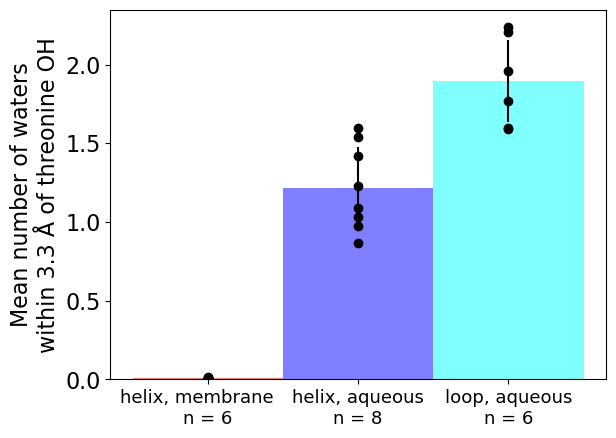

In [6]:
helixdict = {0:"loop", 1:"mixed", 2:"helix"}
hbonddict = {0:"membrane", 1:"interfacial", 2:"aqueous"}

colors = ["red","blue","cyan"]
pairs = [[2,0],[2,2],[0,2]]
nwaters_by_site_type = [[] for _ in range(len(pairs))]

spacing = 1
bar_width=spacing
x0 = 0
legend = []

for i, p in enumerate(pairs):
    x = i*spacing+x0
    for r in helix_solv_rotamers_bothproteins:
        if r[0] == p[0] and r[1] == p[1]:
            nwaters_by_site_type[i].append(r[5])
            plt.scatter(x,r[5], color = "black", label = "_nolegend_", zorder=100)

    if i == 0:
        legend.append(f"{helixdict[p[0]]}, {hbonddict[p[1]]}    \nn = {len(nwaters_by_site_type[i])}")
    else:
        legend.append(f"{helixdict[p[0]]}, {hbonddict[p[1]]}\nn = {len(nwaters_by_site_type[i])}")


    plt.bar(x, height=(np.mean(nwaters_by_site_type[i])), yerr=(np.std(nwaters_by_site_type[i])), width=bar_width, color = colors[i], alpha=0.5)

resnames = {"thr":"threonine", "ser":"serine"}

#plt.legend(legend)
plt.xticks([0,1,2], legend, fontsize = 13)
plt.yticks(fontsize = 16)
plt.ylabel(f"Mean number of waters\nwithin 3.3 Å of {resnames[whichresn]} OH", fontsize = 16) #TODO include residue name
plt.savefig(f"figures/waters_near_{whichresn}_oh.svg", format="svg", bbox_inches="tight")

#put number of waters in a numpy array
nwaters_arr = -np.ones((len(pairs),max([len(w) for w in nwaters_by_site_type])))
for i, w in enumerate(nwaters_by_site_type):
    for j in range(len(w)):
        nwaters_arr[i,j] = w[j]

np.save(f"numpy_analysis_outputs/{whichresn}_nwaters_by_site_type.npy", nwaters_arr) #TODO include residue name
#nwaters_rounded = [[round(nw, 3) for nw in nwaters_by_site_type[i]] for i in range(len(nwaters_by_site_type))]

[[ 0.0119656   0.00721961  0.01086296  0.0141863   0.01088325  0.01051045
  -1.         -1.        ]
 [ 0.97516739  1.22657085  0.86548967  1.53760109  1.08689947  1.42016292
   1.03093408  1.59954062]
 [ 1.59367676  2.23579451  2.20653874  1.77189467  1.9593171   1.5978009
  -1.         -1.        ]]


(0.0, 2.5)

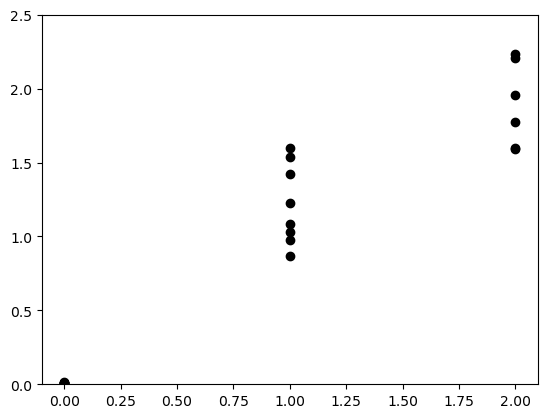

In [7]:
#verify that the saved array is correct

nwaters_arr_l = np.load("figures/nwaters_by_site_type.npy")
print(nwaters_arr_l)
for i, w in enumerate(nwaters_arr_l):
    plt.scatter([i]*len(w), w, color = "black", label = "_nolegend_", zorder=100)
plt.ylim(0,2.5)